### Кусочно-кубическая интерполяция ###

Ниже используется кусочно-кубический эрмитов интерполянт: на каждом $[x_i,x_{i+1}]$ задаётся кубический полином значениями и наклонами в концах. Он имеет непрерывную первую производную, но не обязан сохранять выпуклость и не обязан иметь непрерывную вторую производную.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'

from src.black import implied_vol
from src.interpolation import CubicSplineInterpolator, slopes_estimation
from src.plotting import dark_3d_scatter

In [2]:
surface = pd.read_parquet(PROCESSED_DIR / 'surface.parquet')
surface

,expiration,symbol,last,bid,ask,volume,iv,delta,gamma,open_interest,...,option_kind,log_moneyness,total_variance,call_midf,midf,call_bid,call_ask,call_mid,impl_vol_market,total_variance_market
0,2026-11-05,SPXW261105P07010000,0.20,0.15,0.2,60,0.5752,-0.0024,0.0000,94,...,Put,-0.092453,0.001079,679.099706,0.174999,679.074708,679.124708,679.099708,0.627654,0.001079
1,2026-11-05,SPXW261105P07020000,0.20,0.15,0.2,59,0.5671,-0.0025,0.0000,22,...,Put,-0.091027,0.001049,669.100806,0.174999,669.075807,669.125807,669.100807,0.618852,0.001049
2,2026-11-05,SPXW261105P07025000,0.15,0.15,0.2,18,0.5630,-0.0026,0.0000,447,...,Put,-0.090315,0.001034,664.101356,0.174999,664.076356,664.126356,664.101356,0.614452,0.001034
3,2026-11-05,SPXW261105P07030000,0.15,0.15,0.2,7,0.5590,-0.0026,0.0000,37,...,Put,-0.089604,0.001020,659.101906,0.175000,659.076906,659.126906,659.101906,0.610052,0.001020
4,2026-11-05,SPXW261105P07040000,0.15,0.15,0.2,14,0.5509,-0.0027,0.0000,15,...,Put,-0.088182,0.000990,649.103008,0.175003,649.078005,649.128005,649.103005,0.601255,0.000990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8582,2027-09-30,SPXW270930C09490000,0.00,34.40,35.4,0,0.1290,0.0870,0.0002,0,...,Call,0.175303,0.014982,34.859675,34.859675,34.400000,35.400000,34.900000,0.128762,0.014990
8583,2027-09-30,SPXW270930C09495000,0.00,34.00,35.0,0,0.1290,0.0863,0.0002,0,...,Call,0.175830,0.014978,34.520165,34.520165,34.000000,35.000000,34.500000,0.128695,0.014974
8584,2027-09-30,SPXW270930C09500000,27.40,33.70,34.7,0,0.1289,0.0856,0.0002,102,...,Call,0.176357,0.014979,34.199998,34.199998,33.700000,34.700000,34.200000,0.128713,0.014979
8585,2027-09-30,SPXW270930C09600000,36.12,27.40,28.2,0,0.1284,0.0723,0.0001,25,...,Call,0.186828,0.014857,27.800000,27.800000,27.400000,28.200000,27.800000,0.128189,0.014857


In [3]:
interpolated_smiles = []
arbitrage_cases = []

tolerance = 1e-8

for expiration, smile in surface.groupby('expiration'):
    smile = smile.sort_values('strike').copy()

    strike = smile['strike'].to_numpy()
    call_midf = smile['call_midf'].to_numpy()

    forward = smile['forward'].iloc[0]
    T = smile['T'].iloc[0]
    discount_factor = smile['discount_factor'].iloc[0]

    moneyness = strike / forward
    calls_slopes = slopes_estimation(moneyness, call_midf)

    cubic_spline = CubicSplineInterpolator(x=moneyness, y=call_midf, d=calls_slopes)

    moneyness_grid = np.linspace(moneyness.min(), moneyness.max(), 500)
    strike_grid = moneyness_grid * forward

    interpolated_call_prices = cubic_spline(moneyness_grid).reshape(-1)

    first_derivative = cubic_spline.derivative(moneyness_grid, nu=1).reshape(-1) / forward
    second_derivative = cubic_spline.derivative(moneyness_grid, nu=2).reshape(-1) / forward**2

    vertical_spread_arbitrage = (
        (first_derivative > tolerance)
        | (first_derivative < -discount_factor - tolerance)
    )
    butterfly_arbitrage = second_derivative < -tolerance

    if vertical_spread_arbitrage.any() or butterfly_arbitrage.any():
        arbitrage_cases.append({
            'expiration': expiration,
            'vertical_spread_violations': vertical_spread_arbitrage.sum(),
            'butterfly_violations': butterfly_arbitrage.sum()
        })

    interpolated_option_prices = np.where(
        strike_grid >= forward,
        interpolated_call_prices,
        interpolated_call_prices - discount_factor * (forward - strike_grid)
    )

    interpolated_impl_vol = implied_vol(
        forward, T, strike_grid, interpolated_option_prices,
        strike_grid >= forward, discount_factor
    )

    interpolated_smiles.append(pd.DataFrame({
        'expiration': expiration,
        'T': T,
        'strike': strike_grid,
        'forward': forward,
        'discount_factor': discount_factor,
        'moneyness': moneyness_grid,
        'log_moneyness': np.log(moneyness_grid),
        'call_price': interpolated_call_prices,
        'normalized_call_price': interpolated_call_prices / (discount_factor * forward),
        'impl_vol': interpolated_impl_vol,
        'first_derivative': first_derivative,
        'second_derivative': second_derivative,
        'vertical_spread_arbitrage': vertical_spread_arbitrage,
        'butterfly_arbitrage': butterfly_arbitrage
    }))

interpolated_surface = pd.concat(interpolated_smiles, ignore_index=True)
arbitrage_cases = pd.DataFrame(arbitrage_cases)

arbitrage_cases

,expiration,vertical_spread_violations,butterfly_violations
0,2026-11-05,7,74
1,2026-11-06,0,83
2,2026-11-09,5,74
3,2026-11-10,0,85
4,2026-11-11,0,96
5,2026-11-12,0,93
6,2026-11-13,0,89
7,2026-11-16,0,79
8,2026-11-17,0,101
9,2026-11-18,0,79


In [4]:
points = interpolated_surface[
    (interpolated_surface['T'] >= 7 / 365) &
    (interpolated_surface['T'] <= 1) &
    (interpolated_surface['log_moneyness'].abs() <= 0.3)
].dropna(subset=['impl_vol'])

plot_step = max(1, len(points) // 60_000)
plot_points = points.iloc[::plot_step]

fig = dark_3d_scatter(
    x=plot_points['log_moneyness'],
    y=plot_points['T'],
    z=plot_points['impl_vol'] * 100,
    title='SPX interpolated implied volatility smiles',
    zaxis_title='Implied volatility, %',
    name='Interpolated smiles',
    colorscale='Viridis'
)

fig.show(config={'displaylogo': False, 'responsive': True})

Количество экспираций с butterfly-arbitrage: 39 из 39
Общее количество нарушений: 2583
Средняя доля нарушений: 13.25%
Наиболее проблемная экспирация: 17.11.2026 — 101 нарушений из 500


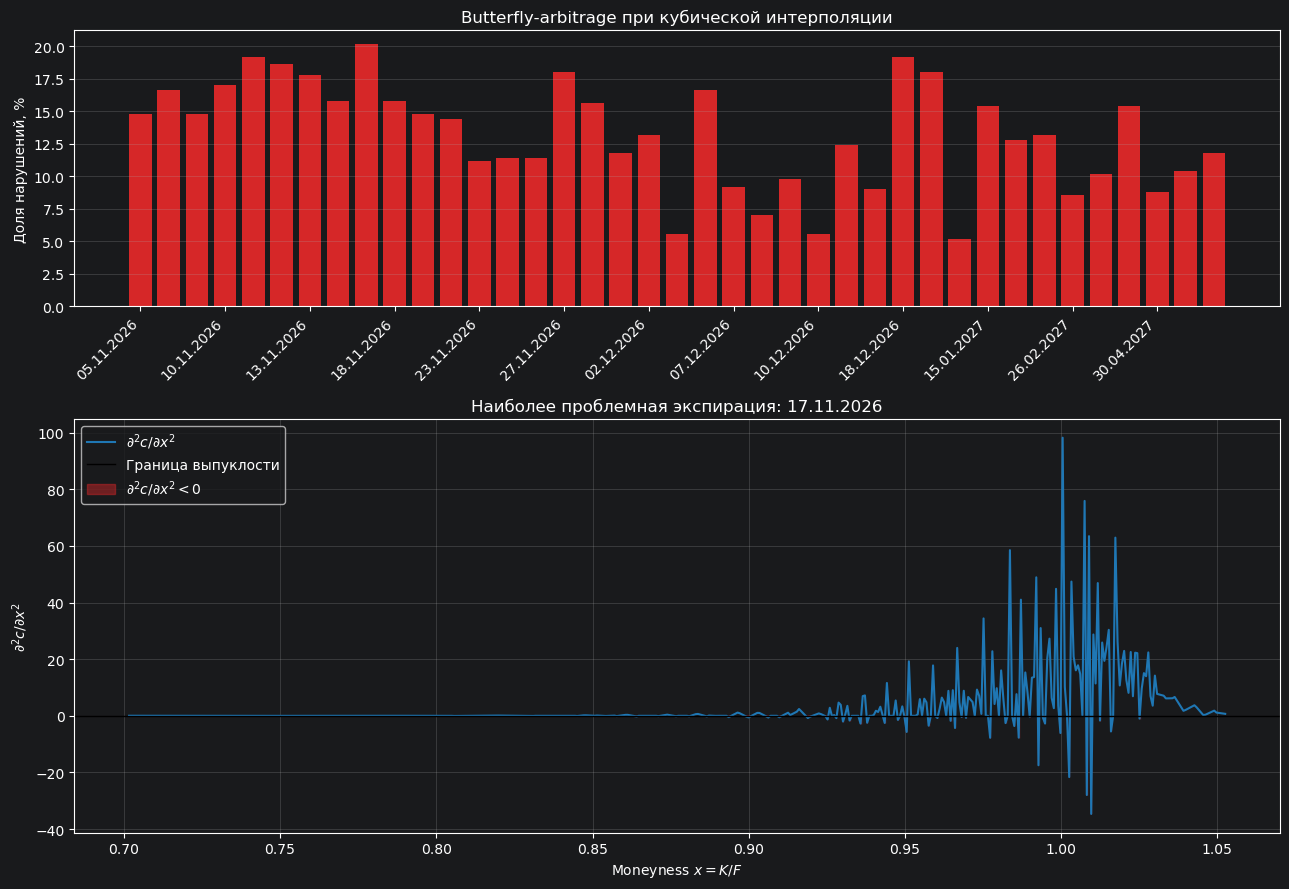

In [5]:
diagnostic_surface = interpolated_surface.copy()
diagnostic_surface['normalized_curvature'] = diagnostic_surface['second_derivative'] * diagnostic_surface['forward'] / diagnostic_surface['discount_factor']

convexity_summary = diagnostic_surface.groupby(['expiration', 'T'], as_index=False).agg(
    butterfly_violations=('butterfly_arbitrage', 'sum'),
    total_points=('butterfly_arbitrage', 'size')
)

convexity_summary['violation_share'] = convexity_summary['butterfly_violations'] / convexity_summary['total_points']

worst_row = convexity_summary.loc[convexity_summary['butterfly_violations'].idxmax()]
worst_expiration = worst_row['expiration']
worst_curve = diagnostic_surface[diagnostic_surface['expiration'] == worst_expiration].sort_values('moneyness')

expirations_with_arbitrage = (convexity_summary['butterfly_violations'] > 0).sum()
total_violations = convexity_summary['butterfly_violations'].sum()
mean_violation_share = convexity_summary['violation_share'].mean()

print(f'Количество экспираций с butterfly-arbitrage: {expirations_with_arbitrage} из {len(convexity_summary)}')
print(f'Общее количество нарушений: {total_violations}')
print(f'Средняя доля нарушений: {mean_violation_share:.2%}')
print(f'Наиболее проблемная экспирация: {worst_expiration:%d.%m.%Y} — {int(worst_row["butterfly_violations"])} нарушений из {int(worst_row["total_points"])}')

fig, axes = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={'height_ratios': [1, 1.5]})

x_positions = np.arange(len(convexity_summary))
bar_colors = np.where(convexity_summary['butterfly_violations'] > 0, 'tab:red', 'tab:gray')
axes[0].bar(x_positions, convexity_summary['violation_share'] * 100, color=bar_colors)

tick_step = max(1, len(convexity_summary) // 10)
tick_positions = x_positions[::tick_step]
tick_labels = convexity_summary['expiration'].dt.strftime('%d.%m.%Y').iloc[::tick_step]

axes[0].set_xticks(tick_positions)
axes[0].set_xticklabels(tick_labels, rotation=45, ha='right')
axes[0].set_ylabel('Доля нарушений, %')
axes[0].set_title('Butterfly-arbitrage при кубической интерполяции')
axes[0].grid(axis='y', alpha=0.3)

axes[1].plot(worst_curve['moneyness'], worst_curve['normalized_curvature'], color='tab:blue', linewidth=1.5, label=r'$\partial^2 c/\partial x^2$')
axes[1].axhline(0, color='black', linewidth=1, label='Граница выпуклости')
axes[1].fill_between(worst_curve['moneyness'], worst_curve['normalized_curvature'], 0, where=worst_curve['butterfly_arbitrage'], color='tab:red', alpha=0.45, label=r'$\partial^2 c/\partial x^2<0$')

axes[1].set_xlabel(r'Moneyness $x=K/F$')
axes[1].set_ylabel(r'$\partial^2 c/\partial x^2$')
axes[1].set_title(f'Наиболее проблемная экспирация: {worst_expiration:%d.%m.%Y}')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

Полученные результаты показывают, что кусочно-кубический эрмитов интерполянт не сохраняет выпуклость call-цены.

Для всех рассматриваемых экспираций существуют области, в которых вторая производная пересекает ноль и становится отрицательной: $\frac{\partial^2C}{\partial K^2}<0$. Это означает появление *butterfly-arbitrage*.

Следовательно, хорошее визуальное качество интерполированных улыбок implied volatility не гарантирует безарбитражность соответствующих опционных цен. Обычный кубический интерполянт не подходит для дальнейшего построения безарбитражной ценовой поверхности без дополнительных ограничений на форму.